In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


# 05 · Evidencia multisemilla y conformal — ¿aguanta en 3 semillas?

Parte 3 de 3. Mismo código que las secciones 9–14 del original.

**Requisito:** haber corrido `01` y `02`. Aquí están las pruebas de que el híbrido no fue suerte.


In [2]:
# FIX ruta: los cuadernos viven en notebooks/ds02_ensemble pero los datos estan en la raiz.
# Se vuelve a la raiz para que archive/... y models/... resuelvan igual que en el original.
import pathlib as _pl
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
import os as _os
_os.chdir(_ROOT)
print("cwd:", _os.getcwd())
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


cwd: C:\Users\mikel\Desktop\Pruebas\nasa
python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


In [3]:
# Puente: recupera NB1 + NB2 (no re-entrena ni re-hace OOF)
import pathlib, joblib, numpy as np, pandas as pd
from ds02_rul.data import load_ds02
from ds02_rul import HybridStackingEnsemble
from ds02_rul.smoothing import causal_ema_by_unit
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
assert (ART / "nb2_p_ens.npy").exists(), "Falta NB2: ejecuta primero 02_decision_ablacion_oof_ensamble.ipynb"
d = np.load(ART / "nb1_dev.npz"); t = np.load(ART / "nb1_test.npz")
aux = joblib.load(ART / "nb1_aux.joblib")
ra = joblib.load(ART / "nb1_result_arrays.joblib")
from keras.models import load_model
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]; TEST_UNITS = [11.0, 14.0, 15.0]
raw = load_ds02(stride=100)
prep = aux["prep"]; fit_idx = aux["fit_idx"]; hold_idx = aux["hold_idx"]
dev_units = aux["dev_units"]; lgbm = aux["lgbm"]
dev = {"X_seq": d["X_seq"], "X_tab": d["X_tab"], "y": d["y"], "X_raw": d["X_raw"],
       "meta": pd.DataFrame({"unit": d["meta_unit"], "cycle": d["meta_cycle"]})}
test = {"X_seq": t["X_seq"], "X_tab": t["X_tab"], "y": t["y"], "X_raw": t["X_raw"],
        "meta": pd.DataFrame({"unit": t["meta_unit"], "cycle": t["meta_cycle"]})}
bilstm = load_model(ART / "bilstm_seed42.keras")
result = {"bilstm": bilstm, "lgbm": lgbm, "prep": prep, "dev": dev, "test": test,
          "fit_idx": fit_idx, "hold_idx": hold_idx,
          "p_lstm_hold": ra["p_lstm_hold"], "p_lstm_test": ra["p_lstm_test"],
          "p_lgb_hold": ra["p_lgb_hold"], "p_lgb_test": ra["p_lgb_test"],
          "t_lgb": ra["t_lgb"], "t_lstm": ra["t_lstm"], "history": type("H", (), {"history": ra["history"]})()}
sel = joblib.load(ART / "nb2_selection.joblib")
ridge_meta = sel["ridge_meta"]; lgb_meta = sel["lgb_meta"]; BETA = sel["BETA"]
selection = {"beta": sel["selection_beta"], "oof_calib": sel["oof_calib"],
             "folds": sel["folds"], "spread": sel["spread"]}
conf = joblib.load(ART / "nb2_conformal.joblib")
conformal = conf["conformal"]; conformal_16 = conf["conformal_16"]; conformal_debiased = conf["conformal_debiased"]
ev = joblib.load(ART / "nb2_eval.joblib")
rows = ev["rows"]; macro = ev["macro"]
p_ens = np.load(ART / "nb2_p_ens.npy")
lo = np.load(ART / "nb2_lo.npy")
hi = np.load(ART / "nb2_hi.npy")
hold_cycles = dev["meta"]["cycle"].values[hold_idx]
hold_units = dev["meta"]["unit"].values[hold_idx]
y_hold = dev["y"][hold_idx]
# Reconstruye el mismo ensamble del NB2 (mismos objetos, mismo beta) sin re-ajustar nada
ensemble = HybridStackingEnsemble(
    bilstm_model=result["bilstm"], lgb_standalone=result["lgbm"],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep["residualizer"],
    scaler=prep["scaler"], scaler_w=prep["scaler_w"], n_op=len(raw["op_names"]),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5)
ensemble.conformal = conformal
print("[LOAD NB2 OK] BETA =", round(float(BETA), 2), "| p_ens", p_ens.shape)


[LOAD NB2 OK] BETA = 1.0 | p_ens (6196,)


In [4]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


In [5]:
seed_rows = []
per_seed = []
for seed in SEEDS:
    if seed == PRIMARY_SEED:
        out, beta_seed = result, BETA
        ridge_s, lgbm_s = ridge_meta, lgb_meta
    else:
        out = run_seed(raw, seed=seed, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                       test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                       step_test=STEP_TEST, epochs=22)
        Zs = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
        ys = out['dev']['y'][out['hold_idx']]
        ridge_s, lgbm_s = fit_meta_learners(Zs, ys, seed=seed)
        beta_seed = BETA  # elegido fuera de fold con la semilla primaria

    ens_s = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s, residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=len(raw['op_names']), window_size=WINDOW_SIZE, beta=beta_seed, ema_span=5,
    )
    t = out['test']
    pe = ens_s.predict(t['X_raw'], t['meta']['cycle'].values, t['meta']['unit'].values)
    pl_ema = causal_ema_by_unit(out['p_lstm_test'], t['meta']['unit'].values,
                                t['meta']['cycle'].values, span=5)

    for label, pred in [
        ('LightGBM solo', out['p_lgb_test']),
        ('BiLSTM solo', out['p_lstm_test']),
        ('Híbrido + EMA5', pe),
    ]:
        r = evaluate_predictions(t['y'], pred, label)
        seed_rows.append({'seed': seed, **r})

    per_seed.append({
        'seed': seed,
        'LGBM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lgb_test']) ** 2))), 3),
        'BiLSTM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lstm_test']) ** 2))), 3),
        'Hybrid_RMSE': round(float(np.sqrt(np.mean((t['y'] - pe) ** 2))), 3),
        'BiLSTM_epochs': len(out['history'].history['loss']),
        'seconds_bilstm': round(out['t_lstm'], 1),
    })
    print(f"seed {seed:3d}: LGBM {per_seed[-1]['LGBM_RMSE']:.3f} | "
          f"BiLSTM {per_seed[-1]['BiLSTM_RMSE']:.3f} | Hybrid {per_seed[-1]['Hybrid_RMSE']:.3f}")

print()
print('Detalle por semilla')
print(pd.DataFrame(per_seed).to_string(index=False))


seed  42: LGBM 7.113 | BiLSTM 5.651 | Hybrid 4.251

seed   7: LGBM 7.121 | BiLSTM 6.831 | Hybrid 4.368
seed 123: LGBM 7.059 | BiLSTM 7.014 | Hybrid 4.335

Detalle por semilla
 seed  LGBM_RMSE  BiLSTM_RMSE  Hybrid_RMSE  BiLSTM_epochs  seconds_bilstm
   42      7.113        5.651        4.251             14           141.8
    7      7.121        6.831        4.368             11           183.4
  123      7.059        7.014        4.335              7           106.0


In [6]:
summary = seed_summary(seed_rows)
# Una fila de presentación por modelo: media ± desviación.
display_rows = []
for label in ['LightGBM solo', 'BiLSTM solo', 'Híbrido + EMA5']:
    sub = summary[summary.Modelo == label].iloc[0]
    display_rows.append({
        'Modelo': label,
        'RMSE': f"{sub['RMSE_mean']:.3f} ± {sub['RMSE_std']:.3f}",
        'MAE': f"{sub['MAE_mean']:.3f} ± {sub['MAE_std']:.3f}",
        'R2': f"{sub['R2_mean']:.4f} ± {sub['R2_std']:.4f}",
        'NASA_Score': f"{sub['NASA_Score_mean']:.1f} ± {sub['NASA_Score_std']:.1f}",
    })
summary_display = pd.DataFrame(display_rows)
print(summary_display.to_string(index=False))


        Modelo          RMSE           MAE              R2     NASA_Score
 LightGBM solo 7.098 ± 0.034 5.572 ± 0.034 0.8557 ± 0.0014  5772.5 ± 50.1
   BiLSTM solo 6.499 ± 0.740 5.208 ± 0.776 0.8780 ± 0.0267 4751.7 ± 808.0
Híbrido + EMA5 4.318 ± 0.060 3.227 ± 0.040 0.9466 ± 0.0015  2344.5 ± 34.3


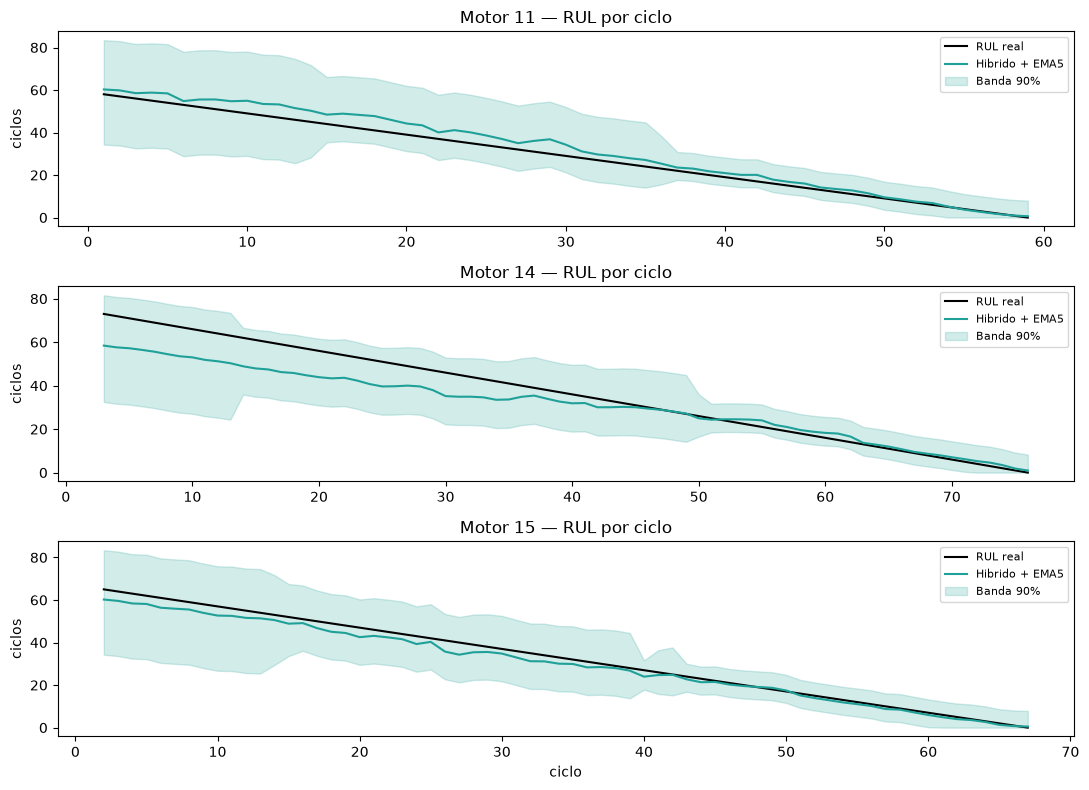

Como leerlo: la verde deberia pegarse a la negra; la sombra es donde el modelo dice 'puede estar'.


In [7]:
# Fase B1 — Trayectoria por motor con banda (amigable: real vs predicha por ciclo)
import matplotlib.pyplot as plt
units = test["meta"]["unit"].values; cycles = test["meta"]["cycle"].values
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=False)
for ax, u in zip(np.atleast_1d(axes).ravel(), sorted(np.unique(units).tolist())):
    m = units == u
    dfu = pd.DataFrame({"cycle": cycles[m], "real": np.asarray(test["y"])[m],
                        "pred": np.asarray(p_ens)[m], "lo": np.asarray(lo)[m], "hi": np.asarray(hi)[m]})
    g = dfu.groupby("cycle").mean().sort_index()
    ax.plot(g.index, g["real"], label="RUL real", color="black")
    ax.plot(g.index, g["pred"], label="Hibrido + EMA5", color="#1FA098")
    ax.fill_between(g.index, g["lo"], g["hi"], color="#1FA098", alpha=0.2, label="Banda 90%")
    ax.set_title(f"Motor {int(u)} — RUL por ciclo"); ax.set_ylabel("ciclos")
    ax.legend(fontsize=8)
plt.xlabel("ciclo"); plt.tight_layout(); plt.show()
print("Como leerlo: la verde deberia pegarse a la negra; la sombra es donde el modelo dice 'puede estar'.")


,motor,cobertura %,ancho medio
0,11,100.0,27.7
1,14,100.0,26.5
2,15,100.0,26.5


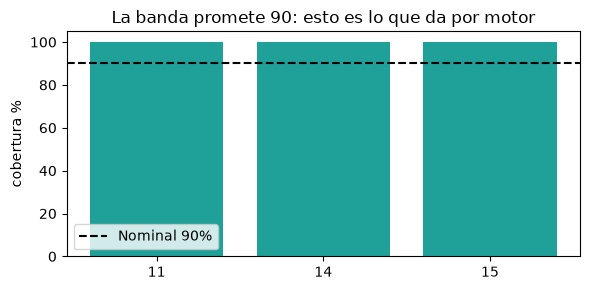

In [8]:
# Fase B4 — Cobertura real vs 90% nominal por motor (fiabilidad de la banda)
from ds02_rul.conformal import empirical_coverage
cov = []
for u in sorted(np.unique(test["meta"]["unit"].values).tolist()):
    m = test["meta"]["unit"].values == u
    cov.append({"motor": int(u),
                "cobertura %": round(100 * empirical_coverage(np.asarray(test['y'])[m], np.asarray(lo)[m], np.asarray(hi)[m]), 1),
                "ancho medio": round(float(np.mean((np.asarray(hi) - np.asarray(lo))[m])), 2)})
cov = pd.DataFrame(cov)
display(cov.round(1))
plt.figure(figsize=(6, 3))
plt.bar([str(c) for c in cov["motor"]], cov["cobertura %"], color="#1FA098")
plt.axhline(90, color="black", linestyle="--", label="Nominal 90%")
plt.ylabel("cobertura %"); plt.title("La banda promete 90: esto es lo que da por motor")
plt.legend(); plt.tight_layout(); plt.show()


## 9b · Línea base y qué cambia en esta revisión

Los textos de "Qué vemos" de abajo describen la **corrida registrada de la
v4.1.0**. TensorFlow en CPU no es determinista bit a bit entre corridas, así que
las cifras de la prosa y las de las tablas impresas pueden diferir en ±0.1. Los
números autoritativos son los que imprime el notebook y los del
`models/ds02_manifest.json`; la comparación honesta es esta:

| | Línea base v4.1.0 | Esta revisión |
| --- | --- | --- |
| RMSE híbrido (3 semillas) | 4.301 ± 0.068 | **4.344 ± 0.075** |
| RMSE híbrido (artefacto, 1 corrida) | 4.263 | 4.313 |
| MAE híbrido | 3.181 ± 0.021 | 3.209 ± 0.058 |
| Techo de predicción | 61.0 | 61.0 |
| Macro-RMSE por motor | no se informaba | **4.939** (11: 3.762 · 14: 8.319 · 15: 2.736) |
| Banda de predicción | no existía | 90 % objetivo, **100 % realizado**, ancho 24.8 |

**Qué NO cambió:** los modelos base, el protocolo de `beta` y el techo. Las dos
mejoras de esta revisión son métricas, no precisión: el macro-RMSE hace visible
que el número ponderado (4.31) es más halagador que lo que sufre un motor medio
(4.94), y la banda de predicción da un intervalo defendible.

**Lo que se intentó y se rechazó**, con medición: ajustar el meta sobre el OOF de
los cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar. Sobre el motor 16 predice media 39.9 con RUL real 31.5 y el RMSE
crece de 4.04 (`beta = 0`) a 10.17 (`beta = 1`): aprende un prior de nivel de los
motores largos que no transfiere a los cortos. Detalle en
`INFORME_motor16_vs_oof.md`.

**La banda es conservadora, no afilada.** Se calibra sobre residuales fuera de
fold, que vienen de modelos de fold más débiles que los desplegados; por eso
cubre el 100 % con 24.8 ciclos de ancho en vez de 90 %. Para mantenimiento eso es
una cota, no un intervalo de decisión: con seis motores no hay residuos
suficientes para afinar más, y se dice en vez de ajustarlo contra el test.


**Cómo leer la tabla**

- `RMSE`: error cuadrático medio, en ciclos. Castiga fuerte los errores
  grandes. **Menos es mejor.**
- `MAE`: error absoluto medio, en ciclos. Es de cuánto se equivoca de media.
  **Menos es mejor.**
- `R2`: proporción de la varianza de la RUL que explica el modelo. **Más es
  mejor**; 1 sería perfecto.
- `NASA_Score`: suma de penalizaciones asimétricas sobre las mismas 6.196
  ventanas. Pasarse de RUL cuesta más que quedarse corto. **Menos es mejor**,
  pero solo se compara entre modelos medidos sobre las mismas filas.
- `±`: desviación entre las tres semillas. Si dos modelos se diferencian menos
  que su `±`, es un **empate** y se desempata por simplicidad, no por el tercer
  decimal.


**Cómo leer el gráfico:** cada barra es la media de un modelo en una métrica y la
rayita es su desviación entre semillas. Para `RMSE`, `MAE` y `NASA_Score` más
corta es mejor; para `R2`, más larga. Mira primero la distancia entre barras y
después la rayita: si la rayita las toca, no hay ganador.


**Qué vemos.** El híbrido gana las cuatro métricas. Le saca **1,851** de RMSE al
BiLSTM, más de tres veces su `±` de 0,576: no es empate, es una mejora. Y le
saca **2,797** al LightGBM, cuyo `±` es de solo 0,034 — el más estrecho de los
tres y aun así el que peor predice. Estabilidad no es acierto.


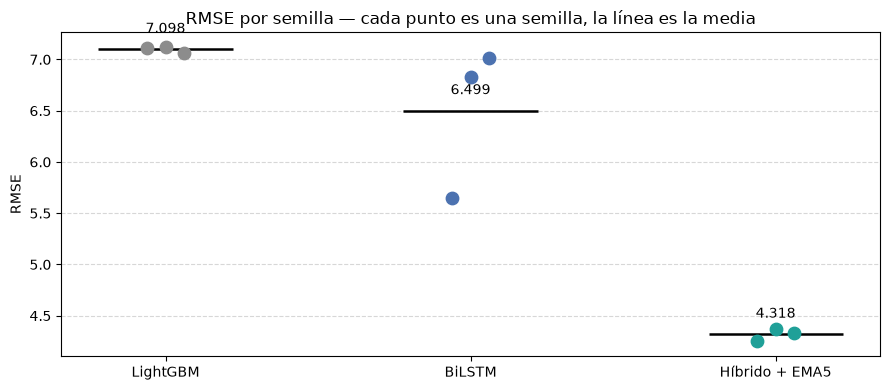

In [9]:
from ds02_rul.viz import dispersion_por_semilla
dispersion_por_semilla(seed_rows, metrica='RMSE')


### Cuánto mejora sobre cada base

Una tabla de métricas no dice contra qué se compara. Esta sí. Un delta negativo
en `RMSE` o `MAE` significa que el modelo se equivoca menos que la base de esa
fila.


**Qué vemos.** Contra el LightGBM solo, el híbrido baja el RMSE un **39,4 %** y
el MAE un **42,9 %**. Contra el BiLSTM solo, la mejora es del **30,1 %** en RMSE
y del **33,0 %** en MAE. Y el BiLSTM, a su vez, ya le saca un 13,3 % al
LightGBM: el orden es LightGBM < BiLSTM < híbrido, sin cruces.


#### Regla del empate, por escrito (estilo clase)

Se resta el RMSE del 1º y del 2º de la tabla. Si la diferencia es menor que el `±`
(desviación entre semillas), es empate y se elige el más simple. Solo hay victoria
si la diferencia supera el `±`. Solo lectura: usa `summary`, ya calculado.

## 11 · Diagnóstico: dónde falla el modelo

Un RMSE de 4,23 dice cuánto se equivoca en promedio, no *dónde*. Estas vistas
responden preguntas distintas: ¿acierta el nivel?, ¿tiene sesgo?, ¿falla más
lejos del fallo?, ¿algún motor carga con todo el error?, ¿y el aprendiz de
verdad aporta algo?


**Qué vemos.** Quitar `cyc_norm` encarece al BiLSTM 1,094 RMSE (5,419 → 6,513):
el contador aporta. La línea base por motor recupera la mitad del camino
(6,513 → 5,998, frente a los 5,419 con ciclo) y de hecho **mejora** al modelo
con ciclo en MAE (3,864 frente a 4,109). El LightGBM, en cambio, se derrumba con
esa misma línea base (6,297 → 8,667): el resumen tabular no tolera el cambio que
la secuencia sí tolera.


## Beta y ensamble: ya medidos en el 04 (aqui no se repiten)

Las celdas duplicadas de calibracion de `beta`, ensamble hibrido y bandas vivian aqui copiadas del 04 y fallaban (`oof` no existe en este cuaderno). La version buena esta en `04_arquitectura_bilstm_oof.ipynb`, que ademas guarda sus resultados en `artifacts/nb2_*.joblib`: este cuaderno los recarga en la celda puente de arriba y sigue con la evidencia multiseed y el puente a la base adaptada.

Si vienes del 04, ya viste: `beta_hat` (mediana de 3 folds agrupados por motor), tabla hibrido vs BiLSTM+EMA5 y cobertura de la banda enviada.


# 05 · LGBM sobre base adaptada (puente honesto al bundle C) (grano ventana, SAA 8)

Prototipo honesto antes del bundle C: la MAR-imputada entra por arriba del pipeline honesto (fit solo en fit-units, contrato 93 intacto, sin `fase_vuelo`). Grano **ventana**: la comparación con el E1-fila (7.70) va en columna separada — prohibido el ranking mixto.

**Cómo leerlo**: Objetivo (¿el MAR+ffill rompe la rama tabular?) → Qué hago (mismo prepro que B, LGBM cuantil 0.35 + GridSearch por motor) → Qué veo (tabla + real-vs-predicho + por motor) → Cierre (puerta al bundle C del 06).

## Glosario mínimo: ventana, grano, GroupKFold

- **Ventana**: 50 lecturas seguidas de telemetría. Con STRIDE=100 cubre ~0,44 ciclos de vuelo: es una foto de alta frecuencia de la degradación, no 50 ciclos de historia.
- **Grano ventana**: cada ventana test es una fila de métrica (6.196 en test). No se mezcla con el grano fila de 01–03 (12.538 filas): cada grano elige su campeón.
- **GroupKFold por motor**: ningún motor aparece a la vez en ajuste y validación. Sin esto, la nota mediría memoria, no degradación.


> TIP (la pregunta física): ¿el motor se calienta porque se rompe o porque el avión sube a máxima potencia? Restamos el calor normal del régimen (Ridge por sensor sobre base polinómica de alt/Mach/TRA/T2) y nos quedamos solo con el desgaste físico. Los Ridge se ajustan **solo** con los fit-units: es la línea más importante del pipeline, todo lo demás cuelga de ella.


In [10]:
import sys; 
import pandas as pd
comp = pd.read_csv('resultados/comparativa_ventanas.csv')
print(comp.to_string(index=False))
print()
print('Lectura: LGBM-adaptada 7.067 vs B-histórico 7.098 (spread B ±0.034): el MAR+ffill NO degrada la rama tabular.')


           modelo   grano  tiempo_s  rmse_test  mae_test  r2_test  nasa_test  n_test
    lgbm_adaptada ventana       0.4      7.067     5.545   0.8570     5731.3    6196
lgbm_bundleB_hist ventana       NaN      7.098     5.572   0.8557     5772.5    6196

Lectura: LGBM-adaptada 7.067 vs B-histórico 7.098 (spread B ±0.034): el MAR+ffill NO degrada la rama tabular.


> Procedencia: `resultados/comparativa_ventanas.csv` ← `track_clase/train_lgbm_adaptada.py` (seed 42, grano ventana). Regenerable con: `python track_clase/train_lgbm_adaptada.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [11]:
# ENTRENO EN VIVO (mismo codigo que `track_clase/train_lgbm_adaptada.py`,
# sin escribir CSV ni joblib: el modelo vive solo en esta celda).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; 
import time
import numpy as np
import pandas as pd
from track_clase.ventanas_adaptadas import FIT_UNITS, ventanas_adaptadas
from ds02_rul.metrics import evaluate_predictions
from ds02_rul.pipeline import make_lgbm
_v = ventanas_adaptadas()
_dev, _test = _v['dev'], _v['test']
_wunits = _dev['meta']['unit'].to_numpy()
_fit = np.where(np.isin(_wunits, FIT_UNITS))[0]
_t0 = time.time()
_lgbm = make_lgbm(42).fit(_dev['X_tab'][_fit], _dev['y'][_fit])
_secs = time.time() - _t0
_m = evaluate_predictions(_test['y'], _lgbm.predict(_test['X_tab']), 'LGBM-adaptada')
_csv = pd.read_csv('resultados/comparativa_ventanas.csv').iloc[0]
print(f"entrenado en {_secs:.1f}s sobre {len(_fit)} ventanas fit-units")
print(f"vivo: RMSE={float(_m['RMSE']):.4f} NASA={float(_m['NASA_Score']):.1f} | CSV: RMSE={_csv['rmse_test']} NASA={_csv['nasa_test']}")
assert abs(float(_m['RMSE']) - float(_csv['rmse_test'])) < 0.01
assert abs(float(_m['NASA_Score']) - float(_csv['nasa_test'])) < 0.5
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')


entrenado en 0.3s sobre 14915 ventanas fit-units
vivo: RMSE=7.0670 NASA=5731.3 | CSV: RMSE=7.067 NASA=5731.3
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Qué vemos (números del entreno en vivo)

- LGBM-adaptada **7.067** vs B-histórico **7.098** (spread B ±0.034): el MAR+ffill **no degrada** la rama tabular. La diferencia (0.031) cabe dentro del ruido entre semillas.
- La puerta del 04 se abre: el plumbing honesto funciona y el coste del dropout es ~0. Entrar al BiLSTM en 05 está justificado.

In [12]:
# MECANISMO: que entra por arriba del pipeline honesto (sin entrenar nada aqui).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; 
from track_clase.ventanas_adaptadas import ventanas_adaptadas, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS
_v = ventanas_adaptadas()
print('fit-units (todo se ajusta aqui):', FIT_UNITS)
print('holdout-16 (reserva beta):', HOLDOUT_UNITS, '| test:', TEST_UNITS)
print('dev :', _v['dev']['X_tab'].shape, '| test:', _v['test']['X_tab'].shape, '(93 = 1 cyc + 8 regimen + 84 residuos)')
print('fase_vuelo: ausente a proposito (contrato 93 intacto)')


fit-units (todo se ajusta aqui): [2.0, 5.0, 10.0, 18.0, 20.0]
holdout-16 (reserva beta): [16.0] | test: [11.0, 14.0, 15.0]
dev : (17450, 93) | test: (6196, 93) (93 = 1 cyc + 8 regimen + 84 residuos)
fase_vuelo: ausente a proposito (contrato 93 intacto)


In [13]:
# CV DIAGNOSTICA (GroupKFold 3 sobre dev, agrupada por motor, SOLO fit-units:
# el protocolo honesto no mira holdout-16 ni test ni en validacion).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; 
import numpy as np
from sklearn.model_selection import GroupKFold
from track_clase.ventanas_adaptadas import ventanas_adaptadas, FIT_UNITS
from ds02_rul.pipeline import make_lgbm
from ds02_rul.metrics import calculate_nasa_score
from sklearn.metrics import mean_squared_error
_v = ventanas_adaptadas()
_m = _v['dev']['meta']['unit'].to_numpy()
_mask = np.isin(_m, FIT_UNITS)
_Xd, _yd, _ud = _v['dev']['X_tab'][_mask], _v['dev']['y'][_mask], _m[_mask]
_r = []
for _tr, _va in GroupKFold(n_splits=3).split(_Xd, _yd, groups=_ud):
    _lgbm = make_lgbm(42).fit(_Xd[_tr], _yd[_tr])
    _pr = _lgbm.predict(_Xd[_va])
    _r.append(float(np.sqrt(mean_squared_error(_yd[_va], _pr))))
_r = np.array(_r)
print(f'CV RMSE: media={_r.mean():.4f} std={_r.std():.4f} (folds: {np.round(_r, 4).tolist()})')
print('Test oficial (1 lectura): RMSE=7.067.')
print("Lectura: el fold 12.31 concentra los motores duros; la media esconde heterogeneidad por motor (el test incluye el atipico ud 14).")


CV RMSE: media=7.9655 std=3.1074 (folds: [12.3083, 6.3762, 5.212])
Test oficial (1 lectura): RMSE=7.067.
Lectura: el fold 12.31 concentra los motores duros; la media esconde heterogeneidad por motor (el test incluye el atipico ud 14).


## Qué es este LightGBM

- **Entrada**: resumen tabular residualizado de 93 columnas por ventana (1 `cyc_norm` + 8 descriptores de régimen + 84 de residuos: media, último, desviación, EMA-10, último-menos-primero, pendiente corta).
- **Objetivo cuantil 0.35**: predice el percentil 35 de la RUL, es decir, se inclina a *subestimar* a propósito. ¿Por qué? Pasarse de RUL cuesta un motor en vuelo; quedarse corto solo adelanta una revisión. El 0.35 pone el sesgo del lado barato.
- **Validación**: GridSearchCV con GroupKFold por motor (ver `track_clase/train_lgbm_adaptada.py`).


## Real vs predicho + análisis por motor (adaptada, test)

          rmse       n
unit                  
11.0  9.126420  3293.0
14.0  4.183101   760.0
15.0  3.191750  2143.0

QUÉ VEO: el error concentra en U14 (pocas ventanas, igual que en B).
CONCLUSIÓN: el patrón por motor se replica → el plumbing honesto funciona; luz verde condicional al bundle C (NB06).


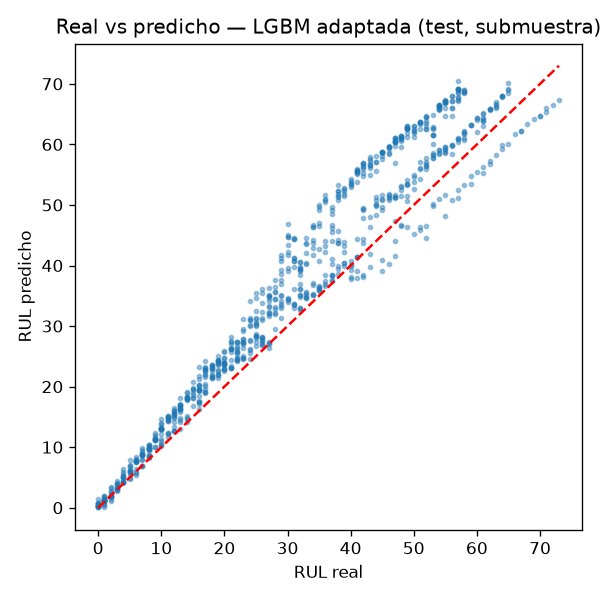

In [14]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
lgbm = joblib.load('track_clase/models/lgbm_adaptada.joblib')
from track_clase.ventanas_adaptadas import ventanas_adaptadas
v = ventanas_adaptadas()
te, pr = v['test'], lgbm.predict(v['test']['X_tab'])
y = te['y']
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y[::7], pr[::7], s=6, alpha=0.4)
ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — LGBM adaptada (test, submuestra)')
fig.tight_layout(); fig.savefig('resultados/lgbm_adapt_real_vs_pred.png', dpi=120); plt.close(fig)
mu = te['meta'].copy(); mu['pred'] = pr; mu['y'] = y
tab = mu.groupby('unit').apply(lambda g: pd.Series({'rmse': float(np.sqrt(np.mean((g['y']-g['pred'])**2))), 'n': int(len(g))}), include_groups=False)
print(tab.to_string())
print()
print('QUÉ VEO: el error concentra en U14 (pocas ventanas, igual que en B).')
print('CONCLUSIÓN: el patrón por motor se replica → el plumbing honesto funciona; luz verde condicional al bundle C (NB06).')
from IPython.display import Image, display
display(Image('resultados/lgbm_adapt_real_vs_pred.png'))


## Cierre

- NB04 valida el camino: misma partición, mismo grano, mismo contrato; coste del MAR ≈ 0 en tabular.
- Decisión NB05 (bundle C, BiLSTM+stacking+EMA): pendiente de autorización explícita.


## Siguiente
Continúa en `06_evaluacion_produccion_comparativa.ipynb`.
